# SpaceX Falcon 9 Exploratory Data Analysis with Data Visualization
This notebook explores relationships between flight parameters, orbits, launch sites, and booster landing success, followed by one-hot encoding feature preparation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/dataset_part_2.csv')
print('Loaded dataset shape:', df.shape)
df.head(3)

Loaded dataset shape: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0


## 1. Flight Number vs. Launch Site
Scatter plot of Flight Number vs Launch Site with landing success hue.

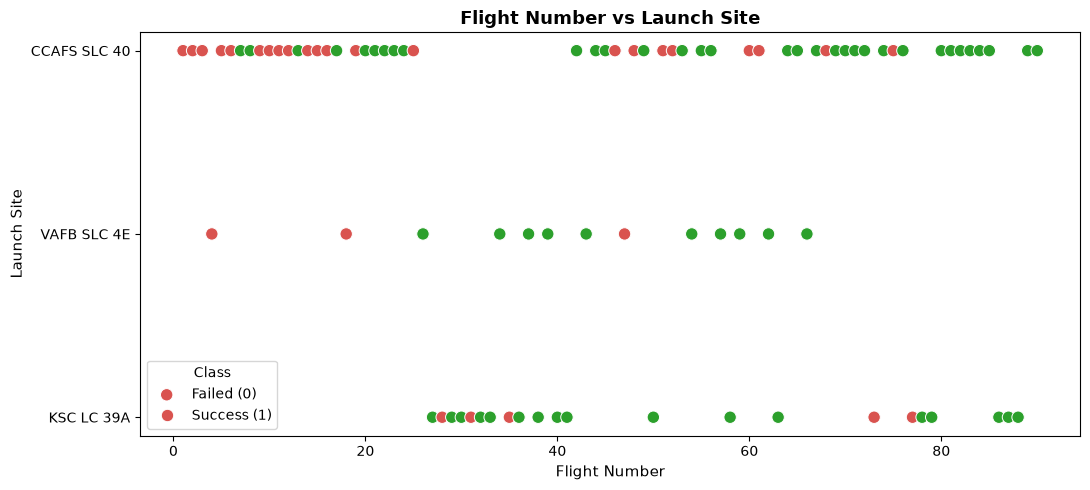

In [2]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x='FlightNumber', y='LaunchSite', hue='Class', palette={0: '#d9534f', 1: '#2ca02c'}, s=80)
plt.title('Flight Number vs Launch Site', fontsize=13, fontweight='bold')
plt.xlabel('Flight Number', fontsize=11)
plt.ylabel('Launch Site', fontsize=11)
plt.legend(title='Class', labels=['Failed (0)', 'Success (1)'])
plt.tight_layout()
plt.show()

## 2. Payload Mass vs. Launch Site
Scatter plot of Payload Mass vs Launch Site.

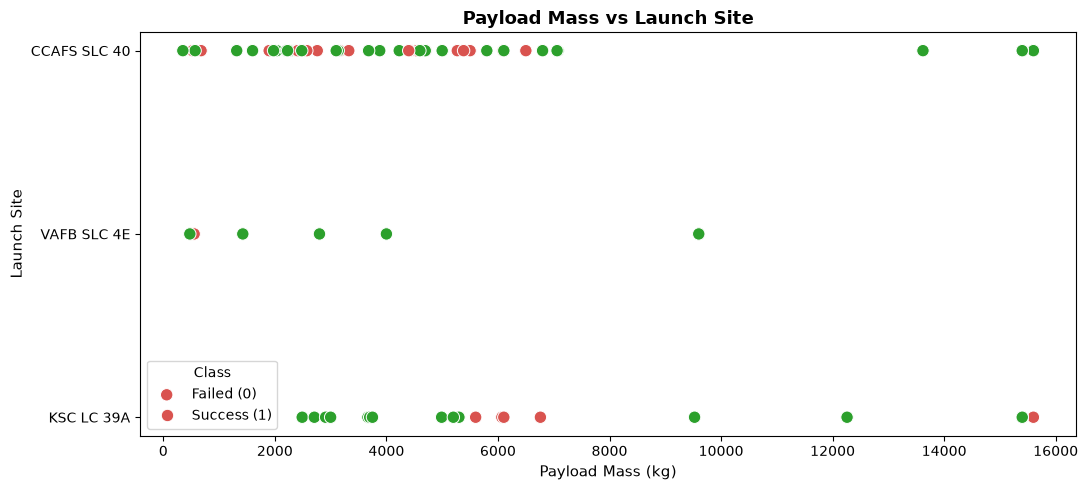

In [3]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x='PayloadMass', y='LaunchSite', hue='Class', palette={0: '#d9534f', 1: '#2ca02c'}, s=80)
plt.title('Payload Mass vs Launch Site', fontsize=13, fontweight='bold')
plt.xlabel('Payload Mass (kg)', fontsize=11)
plt.ylabel('Launch Site', fontsize=11)
plt.legend(title='Class', labels=['Failed (0)', 'Success (1)'])
plt.tight_layout()
plt.show()

## 3. Success Rate by Orbit Type
Bar chart showing landing success percentage across target orbits.

C:\Users\Freiweiss\AppData\Local\Temp\ipykernel_21352\3491622465.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=orbit_success, x='Orbit', y='Class', palette='Blues_r')


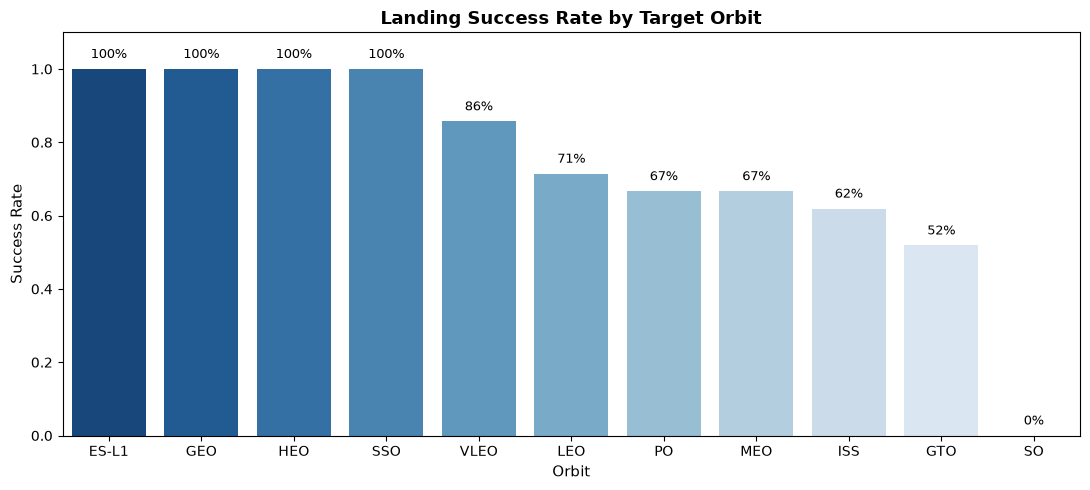

In [4]:
orbit_success = df.groupby('Orbit')['Class'].mean().reset_index().sort_values(by='Class', ascending=False)
plt.figure(figsize=(11, 5))
sns.barplot(data=orbit_success, x='Orbit', y='Class', palette='Blues_r')
plt.title('Landing Success Rate by Target Orbit', fontsize=13, fontweight='bold')
plt.xlabel('Orbit', fontsize=11)
plt.ylabel('Success Rate', fontsize=11)
plt.ylim(0, 1.1)
for i, r in orbit_success.iterrows():
    plt.text(orbit_success.index.get_loc(i), r['Class'] + 0.03, f"{r['Class']*100:.0f}%", ha='center', fontsize=9)
plt.tight_layout()
plt.show()

## 4. Flight Number vs. Orbit Type
Scatter plot showing how target orbits evolved across cumulative flight experience.

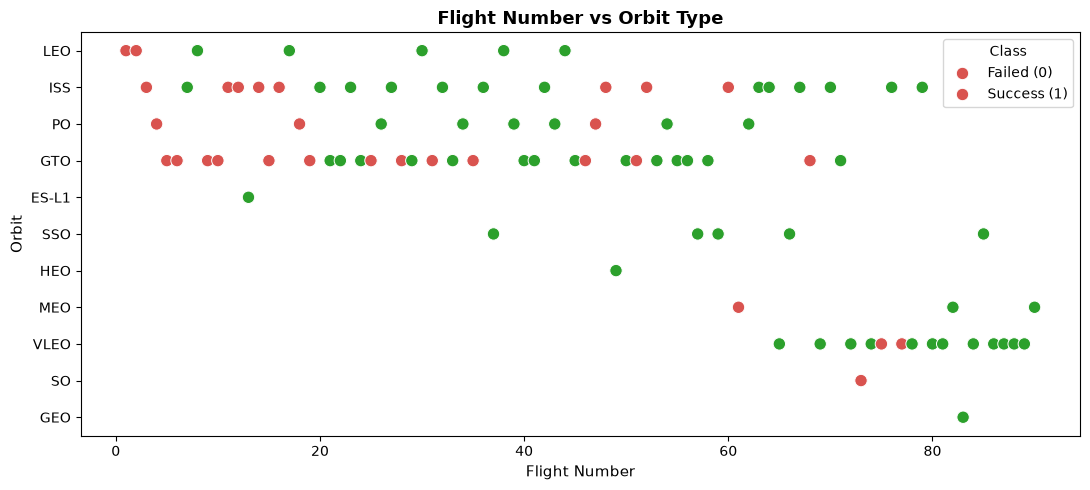

In [5]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x='FlightNumber', y='Orbit', hue='Class', palette={0: '#d9534f', 1: '#2ca02c'}, s=80)
plt.title('Flight Number vs Orbit Type', fontsize=13, fontweight='bold')
plt.xlabel('Flight Number', fontsize=11)
plt.ylabel('Orbit', fontsize=11)
plt.legend(title='Class', labels=['Failed (0)', 'Success (1)'])
plt.tight_layout()
plt.show()

## 5. Payload Mass vs. Orbit Type
Scatter plot analyzing payload mass distribution per orbital profile.

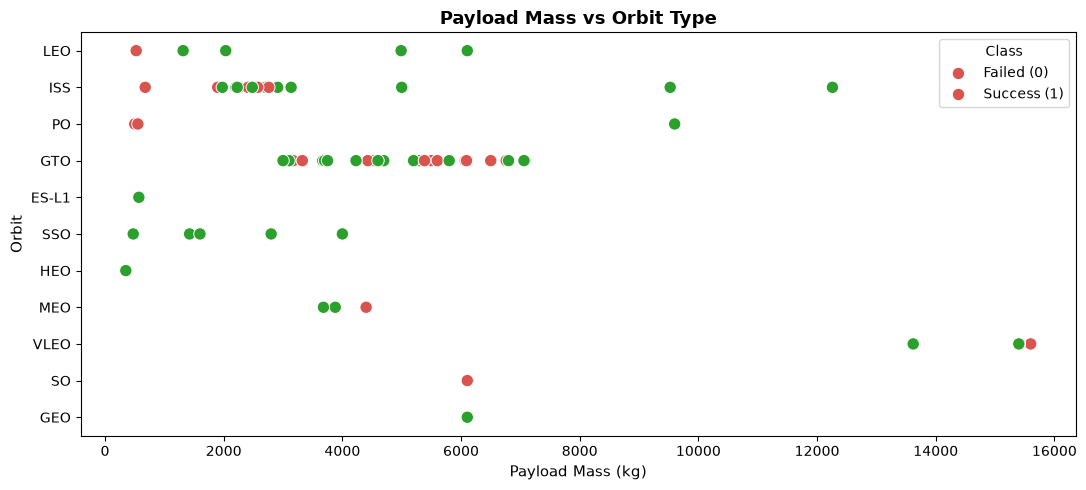

In [6]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x='PayloadMass', y='Orbit', hue='Class', palette={0: '#d9534f', 1: '#2ca02c'}, s=80)
plt.title('Payload Mass vs Orbit Type', fontsize=13, fontweight='bold')
plt.xlabel('Payload Mass (kg)', fontsize=11)
plt.ylabel('Orbit', fontsize=11)
plt.legend(title='Class', labels=['Failed (0)', 'Success (1)'])
plt.tight_layout()
plt.show()

## 6. Yearly Launch Success Trend
Line chart tracking the annual trajectory of landing success rate from 2010 to 2020.

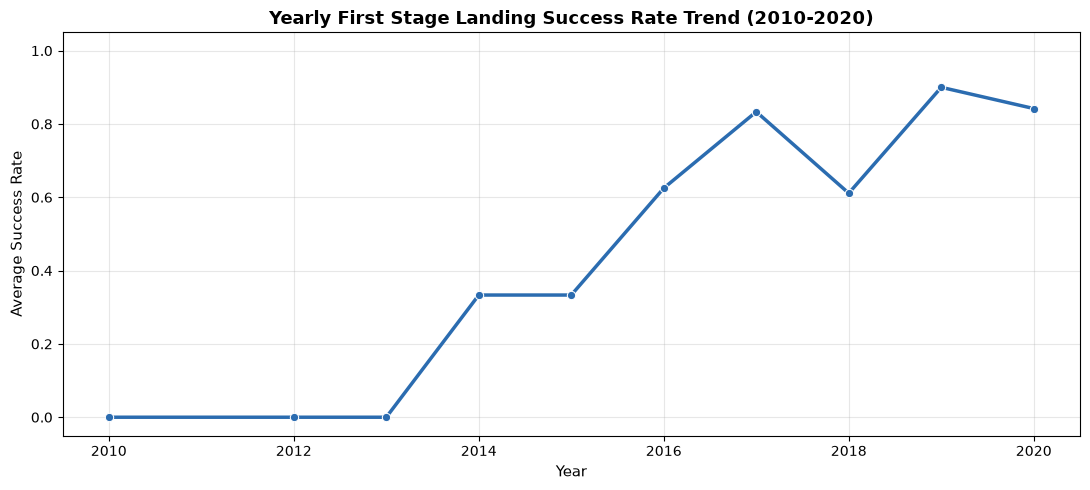

In [7]:
df['Year'] = pd.DatetimeIndex(df['Date']).year
yearly_success = df.groupby('Year')['Class'].mean().reset_index()
plt.figure(figsize=(11, 5))
sns.lineplot(data=yearly_success, x='Year', y='Class', marker='o', color='#2b6cb0', lw=2.5)
plt.title('Yearly First Stage Landing Success Rate Trend (2010-2020)', fontsize=13, fontweight='bold')
plt.xlabel('Year', fontsize=11)
plt.ylabel('Average Success Rate', fontsize=11)
plt.ylim(-0.05, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Feature Engineering & One-Hot Encoding
Select analytical features and apply dummy encoding to categorical attributes.

In [8]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot = features_one_hot.astype('float64')
print('Encoded features shape:', features_one_hot.shape)
features_one_hot.to_csv('../data/dataset_part_3.csv', index=False)
print('Saved dataset_part_3.csv successfully.')

Encoded features shape: (90, 80)
Saved dataset_part_3.csv successfully.
